# Portfolio copy
Adapted from completed course notebooks. We retain the original model and analysis code; Google Drive mounting and the course-specific download link were replaced with local dataset instructions. Saved outputs come from the original notebook runs and have not been regenerated.


# Biomedical Imaging and Pytorch IV:
# Transfer Learning



## 2. **Setting up Our Workspace**



---
**Display Basic GPU Information**

---

En primer lugar, verifico y muestro la GPU disponible.

In [29]:
!nvidia-smi

Sun Nov 30 20:20:58 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 550.54.15              Driver Version: 550.54.15      CUDA Version: 12.4     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   52C    P0             27W /   70W |    1366MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----


---
**Setting our Home**

---


Defino el directorio principal (HOME).

In [30]:
# Configuro nuestra $HOME to /content

import os
HOME = os.getcwd()
print(HOME)

/content/datasets/datasets



---
**Mount Google Drive**

---

Integro Google Drive en mi notebook, autorizando su acceso.

Google Drive mounting was removed from this portfolio copy. Place the dataset archive locally as described in the README.

Creo un directorio donde guardo mi dataset.

In [32]:
# Creo el directorio del dataset
import os
datasets_dir = os.path.join(HOME, "datasets")
os.makedirs(datasets_dir, exist_ok=True)
print(os.getcwd())

/content/datasets/datasets


Descargo el dataset y obtengo nuevos conjuntos de datos.

In [ ]:
import os, zipfile
from pathlib import Path
os.chdir(datasets_dir)
archive = Path("exp4val.zip")
if not archive.is_file():
    raise FileNotFoundError("Place the course dataset archive exp4val.zip in the datasets directory. See README.")
with zipfile.ZipFile(archive) as dataset_zip:
    root = Path.cwd().resolve()
    for member in dataset_zip.infolist():
        if not (root / member.filename).resolve().is_relative_to(root):
            raise ValueError("Unsafe dataset archive path")
    dataset_zip.extractall(root)


Visualizo la estructura de os datos mediante un árbol de directorios: organiza los datos antes de cargarlos.

In [34]:
!apt-get install -q tree

!tree -L 2 -d $datasets_dir

Reading package lists...
Building dependency tree...
Reading state information...
tree is already the newest version (2.0.2-1).
0 upgraded, 0 newly installed, 0 to remove and 41 not upgraded.
/content/datasets/datasets/datasets
├── test
│   ├── class_0
│   ├── class_1
│   ├── class_2
│   ├── class_3
│   ├── class_4
│   ├── class_5
│   └── class_6
├── train
│   ├── class_0
│   ├── class_1
│   ├── class_2
│   ├── class_3
│   ├── class_4
│   ├── class_5
│   └── class_6
└── val
    ├── class_0
    ├── class_1
    ├── class_2
    ├── class_3
    ├── class_4
    ├── class_5
    └── class_6

24 directories


Visualizo 6 imagenes de ejemplo del dataset para comprobar que el formato sea razonable, saber su tamaño (256, 256, 3) con formato jpg.

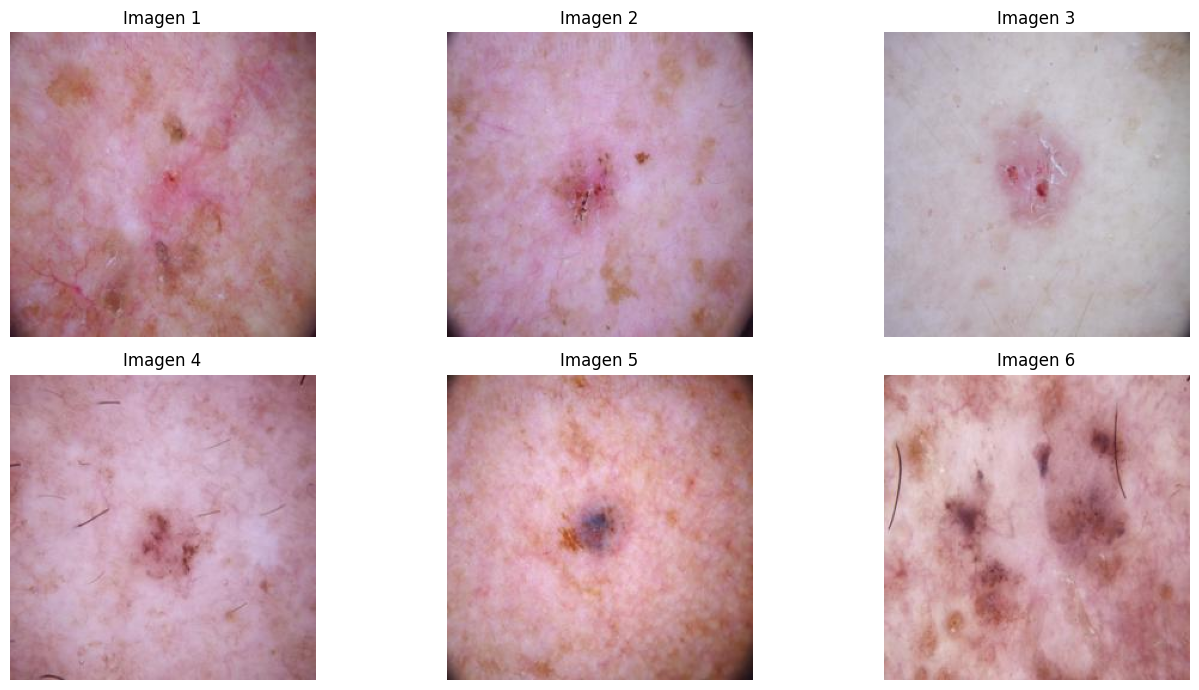


 Size of image:  (256, 256, 3)


In [35]:
# Creo un dibujo con subplots organizados en una cuadrícula de 2x4
import matplotlib.pyplot as plt
import glob
import matplotlib.image as mpimg

# Directorio de las imagenes
image_directory = f'{HOME}/datasets/test/class_1/'

# Lista de rutas de imágenes
image_paths = glob.glob(image_directory + '*.jpg')[:6]

# Configurar el dibujo con los subplots
fig, axs = plt.subplots(2, 3, figsize=(14, 7))

# Iterar a través de las imágenes y mostrarlas en los subplots.
for i, image_path in enumerate(image_paths):
    row = i // 3
    col = i % 3
    img = mpimg.imread(image_path)
    axs[row, col].imshow(img)
    axs[row, col].set_title(f'Imagen {i + 1}')
    axs[row, col].axis('off')

plt.tight_layout()
plt.show()
print("\n Size of image: ", img.shape)

### Setting a Dataloader


---
**Transform the dataloaders for data augmentation**

---

Defino las transformaciones de entrada (augmentación en train, centre crop en val/test) usando tamaño estándar para ResNet.

In [36]:
from torchvision import datasets, models, transforms

data_transforms = {
    'train': transforms.Compose([
        transforms.Resize(256),
        transforms.ColorJitter(brightness=0.2, contrast=0.2),  # Variación ligera
        transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),   # Zoom aleatorio
        transforms.RandomRotation(15),        # Rotaciones leves
        transforms.RandomHorizontalFlip(),    # Volteo horizontal
        transforms.RandomVerticalFlip(),      # Volteo vertical
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    'val': transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    'test': transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
}

Configuramos ImageFolder, dataloaders y parámetros clave. Hemos reducido el batch_size a 16, epochs a 30 y num_workers lo hemos subido a 4.

In [37]:
import torch
from torch.utils.data import DataLoader

# Configuraciones
data_dir = f'{HOME}/datasets'
num_classes = 7
batch_size = 16 # cambiado de 32--> 16 para ResNet50 + 224px (memoria y estabilidad)
num_epochs = 80 # cambiado de 100--> 35 para transfer learning (menos epochs necesarios)




image_datasets = {x: datasets.ImageFolder(os.path.join(data_dir, x),
                                          data_transforms[x])
                  for x in ['train', 'val', 'test']}
dataloaders = {x: DataLoader(image_datasets[x], batch_size=batch_size,
                             shuffle=True, num_workers=4)
               for x in ['train', 'val', 'test']} # num_workers 2--> 4 para throughput

dataset_sizes = {x: len(image_datasets[x]) for x in ['train', 'val', 'test']}

class_names = image_datasets['train'].classes

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

---
**Dataloaders**

---

---
**Initializing a ResNet50 model for transfer learning**

---

Cargamos ResNet50 preentrenada y prepararamos para feature extraction

In [38]:
import torch.nn as nn
import torch.optim as optim
from torchvision import models

# Set parameters for transfer learning
feature_extract = True  # Set to False if you want to fine-tune the entire model

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

# Load the pre-trained ResNet50 model
model_ft = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)

# If feature extraction, freeze all layers' parameters
if feature_extract:
    for param in model_ft.parameters():
        param.requires_grad = False

# Replace the fully connected (fc) layer to match the number of classes
num_ftrs = model_ft.fc.in_features
model_ft.fc = nn.Linear(num_ftrs, num_classes) #Usamos la versión simple para evitar overfitting, para datasets pequeños.

# Move the model to the GPU if available
model_ft = model_ft.to(device)



Estas funciones auxiliares definen utilidades para inicializar el modelo y controlar qué parámetros se entrenan (feature-extraction vs fine-tuning).

In [39]:
import torch.nn as nn
import torch.optim as optim

def set_parameter_requires_grad(model, feature_extracting):
    if feature_extracting:
        for param in model.parameters():
            param.requires_grad = False

# Inicializa un modelo ResNet50 para el transfer learning
def initialize_model(num_classes, feature_extract, use_pretrained=True):
    model_ft = models.resnet50(weights=models.ResNet50_Weights.DEFAULT if use_pretrained else None)
    set_parameter_requires_grad(model_ft, feature_extract)
    num_ftrs = model_ft.fc.in_features
    model_ft.fc = nn.Linear(num_ftrs, num_classes)
    return model_ft

model_ft = initialize_model(num_classes, feature_extract, use_pretrained=True)
model_ft = model_ft.to(device)

---
**Show ResNet50 architecture**

---

Mostramos la arquitectura de ResNet50 con torchinfo (input size batch a 16)

In [40]:
!pip install -q torchinfo

In [41]:
import torchinfo

# Se usa torchinfo.summary para imprimir un resumen del modelo
torchinfo.summary(model=model_ft,
        input_size=(16, 3, 224, 224),
        col_names=["input_size", "output_size", "num_params", "trainable"],
        col_width=20,
        row_settings=["var_names"]
)

Layer (type (var_name))                  Input Shape          Output Shape         Param #              Trainable
ResNet (ResNet)                          [16, 3, 224, 224]    [16, 7]              --                   Partial
├─Conv2d (conv1)                         [16, 3, 224, 224]    [16, 64, 112, 112]   (9,408)              False
├─BatchNorm2d (bn1)                      [16, 64, 112, 112]   [16, 64, 112, 112]   (128)                False
├─ReLU (relu)                            [16, 64, 112, 112]   [16, 64, 112, 112]   --                   --
├─MaxPool2d (maxpool)                    [16, 64, 112, 112]   [16, 64, 56, 56]     --                   --
├─Sequential (layer1)                    [16, 64, 56, 56]     [16, 256, 56, 56]    --                   False
│    └─Bottleneck (0)                    [16, 64, 56, 56]     [16, 256, 56, 56]    --                   False
│    │    └─Conv2d (conv1)               [16, 64, 56, 56]     [16, 64, 56, 56]     (4,096)              False
│    │    

## 4. **Train model**

---
**Define loss and optimizer**

---

Prepararamos el optimizador y la función de pérdida (lr reducido)

In [42]:
# Optimiser configuration

params_to_update = model_ft.parameters()

# If feature extraction is enabled (i.e., we are only updating the final layers),
# we filter the parameters to include only those with requires_grad=True
if feature_extract:
    params_to_update = [param for param in model_ft.parameters() if param.requires_grad]

# Define the optimizer
# We are using Stochastic Gradient Descent (SGD) with a learning rate of 0.001 and momentum of 0.9.
# This optimizer will only update the parameters selected above (those that require gradient computation).
optimizer_ft = optim.SGD(params_to_update, lr=0.0005, momentum=0.9)

# Define the loss function (criterion)
# We are using CrossEntropyLoss, which is commonly used for classification tasks with multiple classes.
criterion = nn.CrossEntropyLoss()

Definimos la función train_model que entrena el modelo por épocas y guarda el mejor modelo según val accuracy.

In [45]:
from tqdm import tqdm  # Import tqdm for progress bar visualization

def train_model(model, dataloaders, criterion, optimizer):
    # Save the initial model weights
    best_model_wts = copy.deepcopy(model.state_dict())
    best_acc = 0.0  # Initialize the best accuracy to zero

    # Ready to store metrics (loss and accuracy for training and validation)
    train_losses = []
    val_losses = []
    train_accuracies = []
    val_accuracies = []

    print(f'Epoch (single step)')
    print('-' * 10)

    # Perform both training and validation in one epoch
    for phase in ['train', 'val']:
        if phase == 'train':
            model.train()  # Set model to training mode
        else:
            model.eval()  # Set model to evaluation mode (no gradient updates)

        running_loss = 0.0  # Accumulate total loss in the current epoch
        running_corrects = 0  # Accumulate total correct predictions

        # Use tqdm to display the progress bar for batches
        with tqdm(dataloaders[phase], unit="batch") as tepoch:
            for inputs, labels in tepoch:
                # Update progress bar with current phase
                tepoch.set_description(f"Phase {phase}")

                # Move input data and labels to the appropriate device (GPU/CPU)
                inputs = inputs.to(device)
                labels = labels.to(device)

                optimizer.zero_grad()  # Zero the parameter gradients

                # Only enable gradient calculation during the training phase
                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)  # Forward pass: Get predictions from the model
                    _, preds = torch.max(outputs, 1)  # Get predicted class
                    loss = criterion(outputs, labels)  # Compute loss

                    if phase == 'train':
                        # Backward pass and optimize during training
                        loss.backward()  # Compute gradients
                        optimizer.step()  # Update model weights

                # Accumulate loss and correct predictions
                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)

                # Update the progress bar with the current loss and accuracy
                tepoch.set_postfix(
                    loss=loss.item(),
                    accuracy=torch.sum(preds == labels.data).item() / inputs.size(0)
                )

        # Calculate epoch-level loss and accuracy
        epoch_loss = running_loss / dataset_sizes[phase]
        epoch_acc = running_corrects.double() / dataset_sizes[phase]

        print(f'{phase} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}')

        # Store training or validation metrics
        if phase == 'train':
            train_losses.append(epoch_loss)
            train_accuracies.append(epoch_acc.item())
        else:
            val_losses.append(epoch_loss)
            val_accuracies.append(epoch_acc.item())

        # Save model if the validation accuracy is the best so far
        if phase == 'val' and epoch_acc > best_acc:
            best_acc = epoch_acc
            best_model_wts = copy.deepcopy(model.state_dict())

    print()

    # Load best weights of this single epoch call
    model.load_state_dict(best_model_wts)

    # Return the model and the recorded metrics
    return model, train_losses, val_losses, train_accuracies, val_accuracies


In [48]:
def train_one_epoch(model, dataloaders, criterion, optimizer):
    model.train()
    running_loss = 0.0
    running_corrects = 0

    for inputs, labels in dataloaders['train']:
        inputs = inputs.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        running_corrects += torch.sum(preds == labels.data)

    epoch_loss = running_loss / len(dataloaders['train'].dataset)
    epoch_acc = running_corrects.double() / len(dataloaders['train'].dataset)

    return epoch_loss, epoch_acc.item()


In [49]:
def evaluate(model, dataloaders, criterion):
    model.eval()
    running_loss = 0.0
    running_corrects = 0

    with torch.no_grad():
        for inputs, labels in dataloaders['val']:
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * inputs.size(0)
            running_corrects += torch.sum(preds == labels.data)

    epoch_loss = running_loss / len(dataloaders['val'].dataset)
    epoch_acc = running_corrects.double() / len(dataloaders['val'].dataset)

    return epoch_loss, epoch_acc.item()


Ejecutamos el entrenamiento añadiendo Early Stopping

In [50]:
#Llama a train_model para entrenar y guarda el mejor estado en best_model.pth.

# Entrenar el modelo con Early Stopping
import copy

early_stop_patience = 7
best_model_wts = copy.deepcopy(model_ft.state_dict())
best_acc = -1
epochs_no_improve = 0

train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

for epoch in range(num_epochs):
    print(f"\nEpoch {epoch+1}/{num_epochs}")

    tr_loss, tr_acc = train_one_epoch(model_ft, dataloaders, criterion, optimizer_ft)
    val_loss, val_acc = evaluate(model_ft, dataloaders, criterion)

    train_losses.append(tr_loss)
    val_losses.append(val_loss)
    train_accuracies.append(tr_acc)
    val_accuracies.append(val_acc)

    print(f"Train Loss: {tr_loss:.4f}  Acc: {tr_acc:.4f}")
    print(f"Val   Loss: {val_loss:.4f}  Acc: {val_acc:.4f}")

    # Early stopping
    if val_acc > best_acc:
        best_acc = val_acc
        best_model_wts = copy.deepcopy(model_ft.state_dict())
        epochs_no_improve = 0
        print(f"Best val Acc improved to {best_acc:.4f}")
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= early_stop_patience:
            print(f"\nEarly stopping executed at epoch {epoch+1}")
            break

# Restore best weights
model_ft.load_state_dict(best_model_wts)

torch.save(model_ft.state_dict(), "best_model.pth")



Epoch 1/80
Train Loss: 0.8678  Acc: 0.6970
Val   Loss: 1.0097  Acc: 0.6543
Best val Acc improved to 0.6543

Epoch 2/80
Train Loss: 0.8772  Acc: 0.6921
Val   Loss: 0.9941  Acc: 0.6419

Epoch 3/80
Train Loss: 0.8568  Acc: 0.6963
Val   Loss: 0.9989  Acc: 0.6533

Epoch 4/80
Train Loss: 0.8659  Acc: 0.6962
Val   Loss: 0.9946  Acc: 0.6476

Epoch 5/80
Train Loss: 0.8576  Acc: 0.6971
Val   Loss: 0.9961  Acc: 0.6571
Best val Acc improved to 0.6571

Epoch 6/80
Train Loss: 0.8568  Acc: 0.6995
Val   Loss: 1.0134  Acc: 0.6486

Epoch 7/80
Train Loss: 0.8699  Acc: 0.6871
Val   Loss: 0.9950  Acc: 0.6457

Epoch 8/80
Train Loss: 0.8590  Acc: 0.6995
Val   Loss: 1.0083  Acc: 0.6467

Epoch 9/80
Train Loss: 0.8599  Acc: 0.6986
Val   Loss: 1.0103  Acc: 0.6448

Epoch 10/80
Train Loss: 0.8512  Acc: 0.7034
Val   Loss: 0.9957  Acc: 0.6552

Epoch 11/80
Train Loss: 0.8505  Acc: 0.7029
Val   Loss: 1.0068  Acc: 0.6448

Epoch 12/80
Train Loss: 0.8536  Acc: 0.7033
Val   Loss: 1.0008  Acc: 0.6571

Early stopping execu

---
**Display the metrics curves model**

---

Dibujamos las curvas de pérdida y precisión de entrenamiento/validación para revisar convergencia.

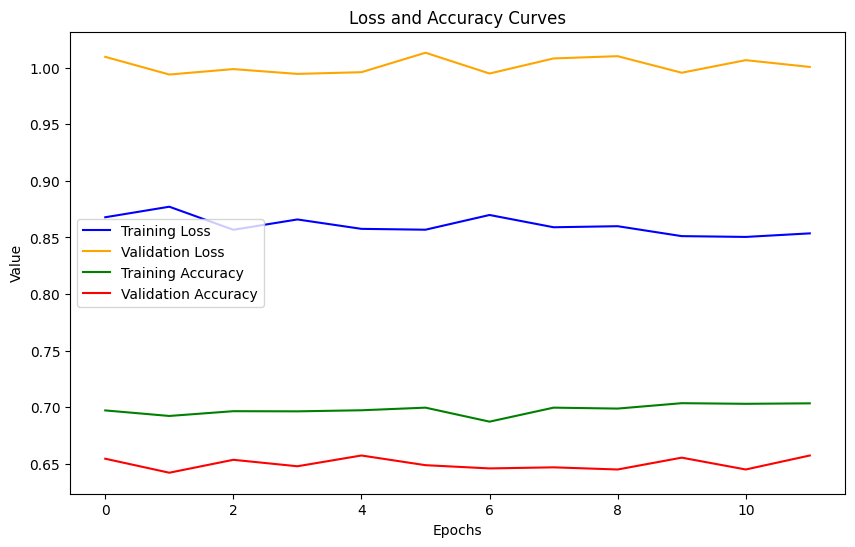

In [51]:
import matplotlib.pyplot as plt

# Create a single subplot in a figure
fig, ax = plt.subplots(figsize=(10, 6))

# Graphing loss curves
ax.plot(train_losses, label="Training Loss", color='blue')
ax.plot(val_losses, label="Validation Loss", color='orange')

# Graphing accuracy curves
ax.plot(train_accuracies, label="Training Accuracy", color='green')
ax.plot(val_accuracies, label="Validation Accuracy", color='red')

# Titles and labels
ax.set_title("Loss and Accuracy Curves")
ax.set_xlabel("Epochs")
ax.set_ylabel("Value")
ax.legend()

# Show the graph
plt.show()


## 5. **Validate our model**

---
**Validation metrics**

---

Recorremos el conjunto test para obtener predicciones, probabilidades y calcular métricas posteriores.

In [52]:
import torch.nn.functional as F
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
import numpy as np  # Import the NumPy library for array manipulation

# Set the model to evaluation mode
# In evaluation mode, dropout and batch normalization behave differently.
# This ensures the model uses fixed parameters for inference rather than stochastic behavior.
model_ft.eval()

# Lists to store predictions, true labels, and probabilities for further evaluation
all_predictions = []
all_labels = []
all_probs = []  # Store probabilities for calculating the ROC curve later

# Disable gradient calculations to speed up inference and save memory
with torch.no_grad():
    # Loop through the test dataset
    for inputs, labels in dataloaders['test']:
        # Move the inputs and labels to the same device as the model (GPU if available)
        inputs = inputs.to(device)
        labels = labels.to(device)

        # Forward pass: Get model outputs (raw scores/logits)
        outputs = model_ft(inputs)

        # Apply softmax to the outputs to get probabilities for each class
        probs = F.softmax(outputs, dim=1)  # dim=1 ensures softmax is applied across class scores

        # Get the class with the highest probability as the predicted class
        _, predicted = torch.max(probs, 1)

        # Store predictions and true labels in the lists (converted to NumPy arrays)
        all_predictions.extend(predicted.cpu().numpy())  # Move predictions to CPU and convert to NumPy
        all_labels.extend(labels.cpu().numpy())  # Move labels to CPU and convert to NumPy

        # Store probabilities for calculating ROC and AUC later
        all_probs.extend(probs.cpu().numpy())  # Move probabilities to CPU and convert to NumPy


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


Calculamos métricas clásicas (accuracy, classification report) y mostramos la matriz de confusión en un heatmap.

Accuracy: 66.19%
              precision    recall  f1-score   support

     class_0       0.54      0.47      0.50        30
     class_1       0.56      0.60      0.58        30
     class_2       0.56      0.60      0.58        30
     class_3       0.75      0.60      0.67        30
     class_4       0.57      0.57      0.57        30
     class_5       0.69      0.83      0.76        30
     class_6       0.97      0.97      0.97        30

    accuracy                           0.66       210
   macro avg       0.66      0.66      0.66       210
weighted avg       0.66      0.66      0.66       210



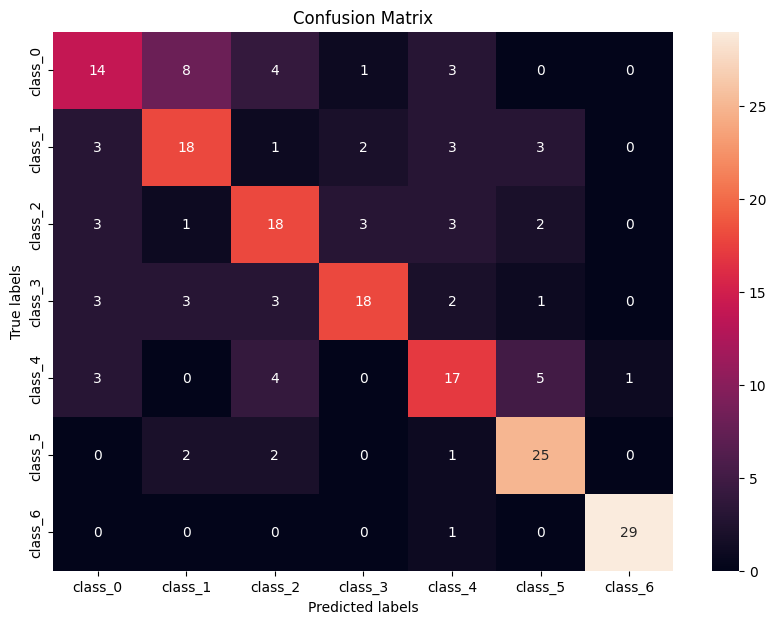

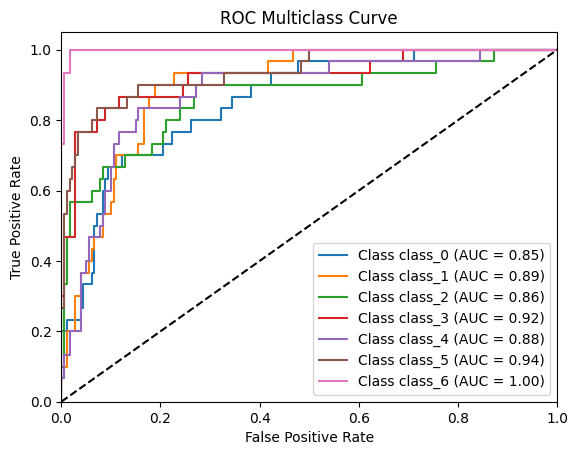

In [53]:
# Calculate accuracy using sklearn's accuracy_score
# This compares all the true labels (all_labels) with the predicted labels (all_predictions)
accuracy = accuracy_score(all_labels, all_predictions)
print(f"Accuracy: {accuracy * 100:.2f}%")  # Output the accuracy as a percentage

# Generate a classification report
# This gives precision, recall, F1-score, and support for each class, using the true labels and predictions
print(classification_report(all_labels, all_predictions, target_names=class_names))

# Create a confusion matrix
# This matrix shows how often each class was predicted correctly or incorrectly
cm = confusion_matrix(all_labels, all_predictions)

# Plot the confusion matrix using a heatmap
plt.figure(figsize=(10, 7))  # Set the size of the figure
sns.heatmap(cm, annot=True, fmt='g', xticklabels=class_names, yticklabels=class_names)  # Display the matrix with annotations
plt.xlabel('Predicted labels')  # X-axis label for predicted classes
plt.ylabel('True labels')  # Y-axis label for true classes
plt.title('Confusion Matrix')  # Title of the plot
plt.show()  # Display the plot

# Prepare for ROC (Receiver Operating Characteristic) curve calculation for a multi-class problem
# Binarize the true labels (one-hot encoding) for each class
y_test_bin = label_binarize(all_labels, classes=range(num_classes))

# Convert the stored probabilities into a NumPy array
y_score = np.array(all_probs)

# Initialize dictionaries to store the false positive rates (fpr), true positive rates (tpr), and AUC scores
fpr = dict()
tpr = dict()
roc_auc = dict()

# Calculate ROC curves and AUC for each class
for i in range(num_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])  # Calculate the FPR and TPR for class i
    roc_auc[i] = auc(fpr[i], tpr[i])  # Calculate the area under the curve (AUC) for class i

# Plot ROC curves for each class
plt.figure()  # Create a new figure for the plot
for i in range(num_classes):
    # Plot the ROC curve for each class and include its AUC in the legend
    plt.plot(fpr[i], tpr[i], label=f'Class {class_names[i]} (AUC = {roc_auc[i]:.2f})')

# Plot a diagonal dashed line representing random chance (AUC = 0.5)
plt.plot([0, 1], [0, 1], 'k--')

# Set limits for the x and y axes
plt.xlim([0.0, 1.0])  # X-axis (False Positive Rate) from 0 to 1
plt.ylim([0.0, 1.05])  # Y-axis (True Positive Rate) from 0 to slightly above 1 for better visualization

# Add labels and a title to the plot
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Multiclass Curve')

# Add a legend in the lower-right corner that shows which class each ROC curve represents
plt.legend(loc="lower right")

# Display the ROC curve plot
plt.show()


## 6. **Predictions** (inference)

---
**Display predictions**

---

Visualizar predicciones (batch) con etiquetas verdaderas y predichas. (Un modelo óptimo debe tener como mínimo un 0.95 o 0.96)

Recupera un batch de test y dibuja cada imagen con su etiqueta verdadera y la predicha por el modelo.

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


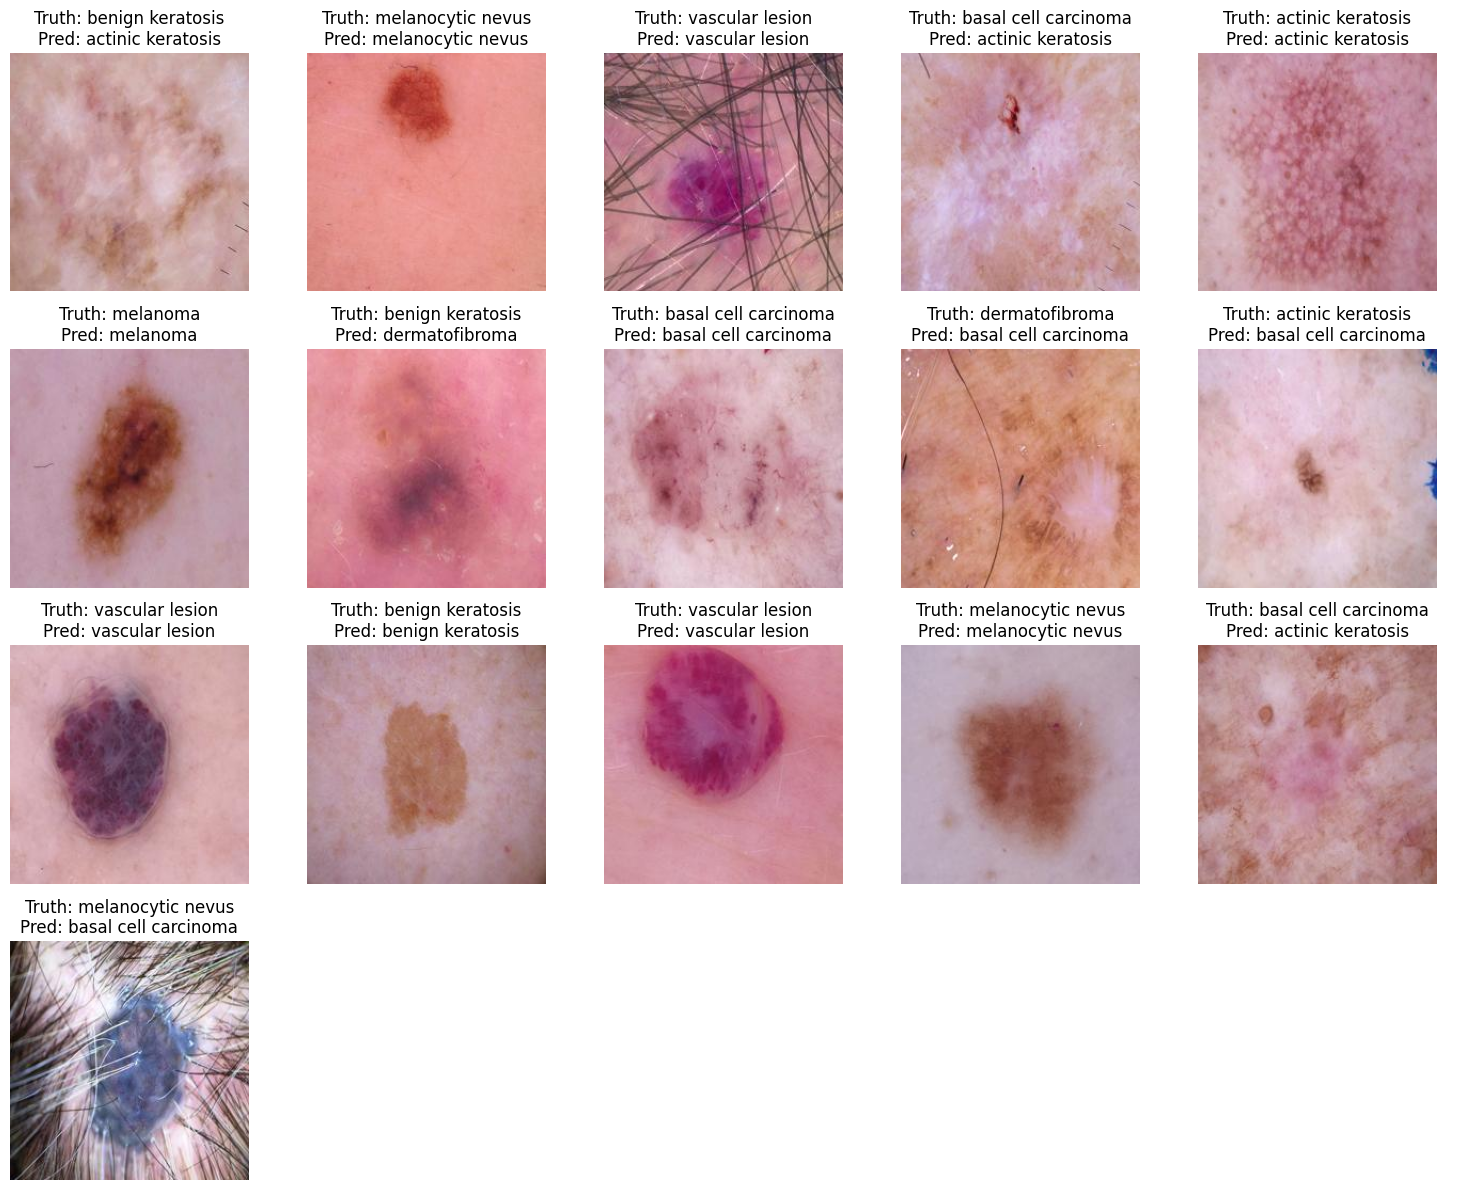

In [54]:
import matplotlib.pyplot as plt

# Define class names corresponding to each label in the dataset
class_names = ['actinic keratosis', 'basal cell carcinoma', 'benign keratosis',
               'dermatofibroma', 'melanoma', 'melanocytic nevus', 'vascular lesion']

# Retrieve a batch of images from the test dataloader
data_iter = iter(dataloaders['test'])
images, labels = next(data_iter)  # Get the next batch of test images and their corresponding labels

# Move the images and labels to CPU (if they're on GPU)
images = images.cpu()
labels = labels.cpu()

# Set the model to evaluation mode
model_ft.eval()

# Make predictions on the batch of images without calculating gradients (for efficiency)
with torch.no_grad():
    # Get model outputs for the batch of images moved to the appropriate device (GPU if available)
    outputs = model_ft(images.to(device))

    # Get the predicted labels by selecting the class with the highest output probability
    _, predicted = torch.max(outputs, 1)

# Move the predictions back to CPU for further processing
predicted = predicted.cpu()

# Determine how many images are in the batch
num_images = len(images)

# Set the number of columns for displaying the images
num_cols = 5  # You can adjust this value based on how many images you'd like per row

# Calculate the number of rows needed to display all images
num_rows = (num_images + num_cols - 1) // num_cols  # Ensures no images are left out

# Create a figure with subplots to display images in a grid
fig, axes = plt.subplots(num_rows, num_cols, figsize=(15, 3 * num_rows))  # Adjust figure size

# Loop through each image in the batch
for i in range(num_images):
    row = i // num_cols  # Determine the row index
    col = i % num_cols  # Determine the column index
    image = images[i]  # Get the image
    label = labels[i]  # Get the true label
    pred = predicted[i]  # Get the predicted label

    # Denormalize the image (reverse the normalization applied during preprocessing)
    # Assumes that normalization during preprocessing used mean and std specific to ImageNet
    mean = [0.485, 0.456, 0.406]
    std = [0.229, 0.224, 0.225]
    image = image * torch.tensor(std).view(3, 1, 1) + torch.tensor(mean).view(3, 1, 1)

    # Convert the image from a PyTorch tensor to a NumPy array and transpose the dimensions for display
    image_np = image.numpy().transpose((1, 2, 0))  # Change (C, H, W) to (H, W, C)

    # Display the image in the appropriate subplot with true and predicted labels
    axes[row, col].imshow(image_np)
    axes[row, col].set_title(f"Truth: {class_names[label]}\nPred: {class_names[pred]}")
    axes[row, col].axis('off')  # Turn off axis labels for a cleaner display

# Hide any unused subplots (if the number of images is less than the total grid size)
for i in range(num_images, num_rows * num_cols):
    row = i // num_cols
    col = i % num_cols
    axes[row, col].axis('off')

# Adjust layout to prevent overlapping elements
plt.tight_layout()

# Display the entire grid of images with their respective labels and predictions
plt.show()


**PROCEDIMIENTO Y CONCLUSIONES**


En primer lugar, cambiamos el batch size y lo dejamos en 32, ya que al principio era demasiado pequeño y hacía que el entrenamiento fuera más ruidoso. Con 32 conseguimos un gradiente más estable y además seguimos aprovechando bien la memoria de la GPU.

También modificamos el número de workers del DataLoader, pasándolo a 4. Esto lo hicimos porque vimos que la carga de datos era un cuello de botella, y aumentando los workers la lectura de imágenes se hace en paralelo y el entrenamiento avanza más rápido.

Otro punto ha sido el learning rate. Lo establecimos finalmente en 0.0005 porque probando otros valores más altos vimos que la pérdida oscilaba mucho y el modelo no terminaba de converger, mientras que con este valor se comportaba de forma más estable.

Añadí un bloque de data augmentation más completo para aumentar la variabilidad de las imágenes:

Rotaciones pequeñas

Cambios de brillo y contraste

Traslaciones

Flip horizontal y vertical

Jitter de color

Así evitamos que el modelo memorice y obligarlo a generalizar mejor.

En el código original, el entrenamiento realizaba todas las épocas sin importar si el modelo seguía mejorando o no.
Lo he modificado añadiendo Early Stopping, evitando entrenar de más cuando ya no mejora y ahorrando tiempo computacional.

El número de épocas lo hemos puesto en 80, aunque el entrenamiento se ha parado mucho antes (en la 12)--> Al pasar 7 épocas sin mejora se para el entrenamiento.

Los resultados obtenidos han sido los siguientes:

Las clases 5 y 6 tienen altos niveles de precisión.

La clase 6 alcanza casi un 97%

La curva ROC muestra AUC altos (0.85–1.00)

El modelo discrimina bien aunque la pérdida de validación no baja mucho.

Aunque el accuracy global todavía no es muy alto (66,19%), las métricas por clase muestran que el modelo distingue bien algunas categorías.

Aun así, el objetivo principal de mejorar el entrenamiento respecto al notebook original sí se ha cumplido.